In [3]:
# ===================== CELL P: shared library =====================
import psutil, os
ram = lambda t="": print(f"[RAM: kernel {psutil.Process().memory_info().rss/1e9:.1f} GB | free {psutil.virtual_memory().available/1e9:.1f} GB | total {psutil.virtual_memory().total/1e9:.0f} GB] {t}")
import os, gc, json, time, glob, random
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, torchvision
from types import SimpleNamespace
from scipy import ndimage as ndi
from sklearn.metrics import balanced_accuracy_score, recall_score
DATASET, RES = "isic2019", 224
DEV = "cuda:0"; assert torch.cuda.is_available(), "turn on a GPU"
SD_REPO = "stable-diffusion-v1-5/stable-diffusion-inpainting"
OUT = f"/kaggle/working/{DATASET}"; CACHE = f"{OUT}/cache"; RUNS = f"{OUT}/runs_{RES}"; GEN = f"{OUT}/gen512"; REP = f"{OUT}/report"
for d in (RUNS, GEN, REP): os.makedirs(d, exist_ok=True)
meta = json.load(open(f"{OUT}/meta.json")); classes, tail = meta["classes"], meta["tail"]; K = len(classes); tail_i = [classes.index(c) for c in tail]

# ---- prompts (descriptive wording: check it with a dermatology source before the final report) ----
STYLE = ", dermatoscope, polarized light, sharp focus, high detail"
NEG = "blurry, low resolution, out of focus, smooth, painting, cartoon, jpeg artifacts, text, watermark"
DESC = {"AK": "a dermoscopy image of actinic keratosis, pink-red area with white-yellow scale and a rough surface on sun-damaged skin",
        "DF": "a dermoscopy image of dermatofibroma, round lesion with a central white scar-like patch and a light brown network at the edge",
        "VASC": "a dermoscopy image of a vascular lesion, well-defined red, purple or dark red round areas",
        "SCC": "a dermoscopy image of squamous cell carcinoma, pink-red crusted or scaly lesion with white-yellow keratin and an irregular surface"}
BASIC = {"AK": "a dermoscopy image of actinic keratosis", "DF": "a dermoscopy image of dermatofibroma",
         "VASC": "a dermoscopy image of a vascular lesion", "SCC": "a dermoscopy image of squamous cell carcinoma"}
assert all(c in DESC for c in tail), "add prompts for this dataset's tail classes"

# ---- 224 data ----
ld = lambda s: (np.load(f"{CACHE}/{RES}_squash_all_{s}_x.npy", mmap_mode="r"), np.load(f"{CACHE}/{RES}_squash_all_{s}_y.npy"))
(Xtr, Ytr), (Xva, Yva), (Xte, Yte) = ld("train"), ld("val"), ld("test")
rows_tr = pd.read_csv(f"{CACHE}/{RES}_squash_all_train_rows.csv"); name2idx = {n: i for i, n in enumerate(rows_tr["image"])}
counts = np.bincount(Ytr, minlength=K); prior = counts / counts.sum()
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)
to_gpu = lambda xb: torch.from_numpy(np.ascontiguousarray(xb)).to(DEV, non_blocking=True).permute(0, 3, 1, 2).float() / 255.0
sharp = lambda a: float(ndi.laplace(np.asarray(a).astype(np.float32).mean(-1)).var())

# ---- classifier training library ----
def augment(x):
    n = x.shape[0]; r = lambda: torch.rand(n, device=DEV)
    ang = (r() * 2 - 1) * np.pi; sc = 0.85 + 0.3 * r(); flip = (r() < 0.5).float() * 2 - 1; tx, ty = (r() * 2 - 1) * 0.1, (r() * 2 - 1) * 0.1
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    th = torch.stack([torch.stack([cos * flip, -sin, tx], 1), torch.stack([sin * flip, cos, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(th, x.shape, align_corners=False), padding_mode="reflection", align_corners=False)
    b = 1 + (r().view(n, 1, 1, 1) * 2 - 1) * 0.15; c = 1 + (r().view(n, 1, 1, 1) * 2 - 1) * 0.15; m = x.mean((1, 2, 3), keepdim=True)
    return ((x - m) * c + m * b).clamp(0, 1)
def make_model():
    m = torchvision.models.efficientnet_b0(weights="DEFAULT"); m.classifier[1] = nn.Linear(1280, K); return m.to(DEV)
def make_loss(kind):                     # weights always come from the ORIGINAL real counts
    w = (1 - 0.999) / (1 - 0.999 ** counts); w = torch.tensor(w / w.sum() * K, dtype=torch.float32, device=DEV)
    return (lambda z, y: F.cross_entropy(z, y, weight=w)) if kind == "cb" else (lambda z, y: F.cross_entropy(z, y))
@torch.no_grad()
def logits_of(model, X):
    model.eval(); out = []
    for i in range(0, len(X), 128):
        x = (to_gpu(X[i:i + 128]) - MEAN) / STD
        with torch.autocast("cuda", dtype=torch.float16): out.append(((model(x).float() + model(x.flip(3)).float()) / 2).cpu())
    return torch.cat(out).numpy()
@torch.no_grad()
def feats_of(model, X):
    model.eval(); out = []
    for i in range(0, len(X), 128):
        x = (to_gpu(X[i:i + 128]) - MEAN) / STD
        with torch.autocast("cuda", dtype=torch.float16): out.append(model.avgpool(model.features(x)).flatten(1).float().cpu())
    return torch.cat(out).numpy()
def train(X, Y, name, seed, loss="cb", epochs=12, bs=64, lr=3e-4, wd=1e-4, save_ckpt=False):
    vf, tf = f"{RUNS}/{name}_s{seed}_val.npy", f"{RUNS}/{name}_s{seed}_test.npy"
    if os.path.exists(tf): print(f"{name}_s{seed} done"); return
    torch.manual_seed(seed); np.random.seed(seed); crit = make_loss(loss); model = make_model()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd); spe = len(Y) // bs
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * spe, pct_start=0.1); scaler = torch.amp.GradScaler("cuda"); best = -1
    print(f"{name}_s{seed}: {len(Y)} training images")
    for ep in range(epochs):
        t0 = time.time(); model.train(); perm = np.random.permutation(len(Y)); tot = 0.0
        for b in range(spe):
            bi = np.sort(perm[b * bs:(b + 1) * bs]); x = (augment(to_gpu(X[bi])) - MEAN) / STD; y = torch.from_numpy(Y[bi]).to(DEV)
            with torch.autocast("cuda", dtype=torch.float16): l = crit(model(x).float(), y)
            opt.zero_grad(set_to_none=True); scaler.scale(l).backward(); scaler.step(opt); scaler.update(); sched.step(); tot += l.item()
        zv = logits_of(model, Xva); vb = balanced_accuracy_score(Yva, zv.argmax(1))
        if vb > best:
            best = vb; np.save(vf, zv); np.save(tf, logits_of(model, Xte))
            if save_ckpt: torch.save(model.state_dict(), f"{RUNS}/{name}_s{seed}_best.pt")
        print(f"  ep {ep + 1}/{epochs} loss {tot / spe:.3f} | val bma {vb:.3f} | {time.time() - t0:.0f}s")
    del model, opt; gc.collect(); torch.cuda.empty_cache()
def val_recall(name, seed):
    z = np.load(f"{RUNS}/{name}_s{seed}_val.npy"); return recall_score(Yva, z.argmax(1), labels=list(range(K)), average=None, zero_division=0)

# ---- DINOv2 embeddings ----
_dino = None
@torch.no_grad()
def dino_embed(arr):
    global _dino
    from transformers import AutoModel
    if _dino is None: _dino = AutoModel.from_pretrained("facebook/dinov2-small").to(DEV).eval()
    out = []
    for i in range(0, len(arr), 128):
        x = to_gpu(arr[i:i + 128])
        with torch.autocast("cuda", dtype=torch.float16): f = _dino(pixel_values=(x - MEAN) / STD).pooler_output.float()
        out.append(F.normalize(f, dim=1).cpu())
    return torch.cat(out).numpy()

# ---- 512 data + masks ----
def load512():
    X = np.load(f"{CACHE}/512_squash_tail_train_x.npy", mmap_mode="r"); rows = pd.read_csv(f"{CACHE}/512_squash_tail_train_rows.csv")
    z = np.load(f"{OUT}/tail_masks.npz", allow_pickle=True); k = {n: i for i, n in enumerate(z["names"])}; src = z["masks"]
    M = np.zeros((len(rows), 512, 512), np.uint8)
    for i, n in enumerate(rows["image"]):
        M[i] = (F.interpolate(torch.from_numpy(src[k[n]])[None, None].float(), size=512, mode="bilinear", align_corners=False)[0, 0] > 0.5).numpy()
    return X, M, rows["class"].values, rows["image"].values

# ---- generator ----
def load_gen(train_lora=False, lora_path=None):
    from diffusers import UNet2DConditionModel, AutoencoderKL, DDPMScheduler
    from transformers import CLIPTextModel, CLIPTokenizer
    from peft import LoraConfig
    tok = CLIPTokenizer.from_pretrained(SD_REPO, subfolder="tokenizer")
    txt = CLIPTextModel.from_pretrained(SD_REPO, subfolder="text_encoder", torch_dtype=torch.float16, low_cpu_mem_usage=True).to(DEV).eval(); gc.collect()   # CHANGED
    @torch.no_grad()
    def enc(p):
        ids = tok(p, padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids.to(DEV); return txt(ids).last_hidden_state
    emb = {}
    for c in tail: emb[(c, "basic")] = enc([BASIC[c]]); emb[(c, "descriptive")] = enc([DESC[c] + STYLE])
    unc = enc([NEG]); del txt; gc.collect(); torch.cuda.empty_cache()
    vae = AutoencoderKL.from_pretrained(SD_REPO, subfolder="vae", torch_dtype=torch.float16, low_cpu_mem_usage=True).to(DEV).eval(); gc.collect()            # CHANGED
    unet = UNet2DConditionModel.from_pretrained(SD_REPO, subfolder="unet", torch_dtype=torch.float16, low_cpu_mem_usage=True).to(DEV); unet.requires_grad_(False); gc.collect()  # CHANGED
    unet.add_adapter(LoraConfig(r=16, lora_alpha=16, init_lora_weights="gaussian", target_modules=["to_q", "to_k", "to_v", "to_out.0"]))
    for p in unet.parameters():
        if p.requires_grad: p.data = p.data.float()
    st = None
    if lora_path and os.path.exists(lora_path):
        st = torch.load(lora_path, map_location=DEV, weights_only=False); nm = dict(unet.named_parameters())
        for n, v in st["lora"].items(): nm[n].data.copy_(v.to(DEV))
    if train_lora: unet.enable_gradient_checkpointing()
    else: unet.eval()
    return SimpleNamespace(vae=vae, unet=unet, emb=emb, unc=unc, SF=vae.config.scaling_factor, nc=DDPMScheduler.from_pretrained(SD_REPO, subfolder="scheduler").config, state=st)
@torch.no_grad()
def generate(G, x, m, cls, kind, steps=20, guide=5.0, seed=0):
    from diffusers import DDIMScheduler
    g = torch.Generator(device=DEV).manual_seed(seed); sch = DDIMScheduler.from_config(G.nc); sch.set_timesteps(steps, device=DEV)
    ml = G.vae.encode((x * (1 - m)).half()).latent_dist.mode() * G.SF; mm = F.interpolate(m, size=ml.shape[-2:], mode="nearest").half()
    cond = torch.cat([G.emb[(c, kind)] for c in cls]); emb = torch.cat([G.unc.expand(len(cond), -1, -1), cond])
    lat = torch.randn(ml.shape, generator=g, device=DEV, dtype=torch.float16)
    for t in sch.timesteps:
        inp = torch.cat([lat, mm, ml], 1); inp = torch.cat([inp, inp]).half()
        with torch.autocast("cuda", dtype=torch.float16): e = G.unet(inp, t, encoder_hidden_states=emb).sample
        eu, ec = e.chunk(2); lat = sch.step((eu + guide * (ec - eu)).half(), t, lat).prev_sample
    out = G.vae.decode(lat / G.SF).sample.float().clamp(-1, 1); soft = F.avg_pool2d(m, 9, 1, 4)
    return x * (1 - soft) + out * soft
down = lambda x: F.interpolate(x, size=224, mode="bilinear", antialias=True, align_corners=False)
to_u8 = lambda g: ((g + 1) * 127.5).round().clamp(0, 255).byte().permute(0, 2, 3, 1).cpu().numpy()
print("P ready | classes", classes, "| tail", tail, "| train", Xtr.shape)

P ready | classes ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC'] | tail ['AK', 'DF', 'VASC', 'SCC'] | train (23056, 224, 224, 3)


In [8]:
ram("after p")

[RAM: kernel 3.5 GB | free 27.4 GB | total 34 GB] after p


In [4]:
# ===================== CELL M0: lesion masks for tail classes =====================
import numpy as np
from scipy import ndimage as ndi
from skimage import color, filters, morphology
if os.path.exists(f"{OUT}/tail_masks.npz"): print("masks exist")
else:
    S = 224; yy, xx = np.mgrid[:S, :S]; rr = np.hypot(yy - S / 2 + .5, xx - S / 2 + .5) / (S / 2); VALID, RING = rr < .97, (rr > .8) & (rr < .97)
    def lesion_mask(img):
        lab = ndi.gaussian_filter(color.rgb2lab(img), (2, 2, 0)); bg = np.median(lab[RING], 0); d = np.linalg.norm(lab - bg, axis=2); d[~VALID] = 0
        m = (d > filters.threshold_otsu(d[VALID])) & VALID
        m = ndi.binary_fill_holes(morphology.closing(morphology.opening(m, morphology.disk(3)), morphology.disk(5))); l, n = ndi.label(m)
        if n: m = l == (int(np.argmax(ndi.sum(m, l, range(1, n + 1)))) + 1)
        ok = 0.03 < m.mean() < 0.80; return (m if ok else rr < .35), ok
    idx = np.where(rows_tr["class"].isin(tail).values)[0]; ms, oks = [], []
    for i in idx: m, ok = lesion_mask(Xtr[i]); ms.append(m.astype(np.uint8)); oks.append(ok)
    np.savez_compressed(f"{OUT}/tail_masks.npz", names=rows_tr["image"].values[idx], masks=np.stack(ms))
    print("masks:", len(idx), "| accepted", round(float(np.mean(oks)) * 100, 1), "%")

masks exist


In [8]:
# ===================== CELL G1: train 512px LoRA generator (low-RAM version) =====================
from diffusers import DDPMScheduler
STEPS, MICRO_BS, ACCUM, LR_G, SAVE_EVERY = 1500, 1, 8, 1e-4, 250      # effective batch 8, half the GPU memory
GC = f"{GEN}/gen_last.pt"
ram("G1 start")
Xt, Mt, Yt, Nt = load512(); by_cls = {c: np.where(Yt == c)[0] for c in tail}; print({c: len(v) for c, v in by_cls.items()}); ram("G1 data loaded")
G = load_gen(train_lora=True, lora_path=GC); G.vae.enable_slicing(); ram("G1 generator loaded")
params = [p for p in G.unet.parameters() if p.requires_grad]
sched = DDPMScheduler.from_pretrained(SD_REPO, subfolder="scheduler"); opt = torch.optim.AdamW(params, lr=LR_G, weight_decay=1e-2); scaler = torch.amp.GradScaler("cuda")
step, hist = 0, []
if G.state:
    opt.load_state_dict(G.state["opt"]); scaler.load_state_dict(G.state["scaler"]); step, hist = G.state["step"], G.state["hist"]; print("resumed from step", step)
    G.state = None; gc.collect()
random.seed(step); np.random.seed(step); torch.manual_seed(step)

def batch():
    cls = [random.choice(tail) for _ in range(MICRO_BS)]; idx = sorted(int(np.random.choice(by_cls[c])) for c in cls)
    cls = [Yt[i] for i in idx]
    x = torch.from_numpy(np.ascontiguousarray(Xt[idx])).to(DEV).permute(0, 3, 1, 2).float() / 127.5 - 1; m = torch.from_numpy(Mt[idx]).to(DEV)[:, None].float()
    if random.random() < 0.5: x, m = x.flip(3), m.flip(3)
    k = random.randint(0, 3); x, m = torch.rot90(x, k, (2, 3)), torch.rot90(m, k, (2, 3))
    kk = random.choice([1, 11, 23, 35]); m = F.max_pool2d(m, kk, 1, kk // 2)
    full = torch.rand(MICRO_BS, device=DEV) < 0.1; m = torch.where(full[:, None, None, None], torch.ones_like(m), m)
    cond = torch.cat([G.emb[(c, random.choice(["basic", "descriptive"]))] for c in cls])
    drop = torch.rand(MICRO_BS, device=DEV) < 0.1; cond = torch.where(drop[:, None, None], G.unc.expand(MICRO_BS, -1, -1), cond)
    return x, m, cond

def save_g():
    torch.save({"lora": {n: p.detach().cpu() for n, p in G.unet.named_parameters() if p.requires_grad}, "opt": opt.state_dict(), "scaler": scaler.state_dict(), "step": step, "hist": hist}, GC)

G.unet.train(); t0 = time.time(); run = []
while step < STEPS:
    opt.zero_grad(set_to_none=True)
    for _ in range(ACCUM):
        x, m, cond = batch()
        with torch.no_grad():
            lat = G.vae.encode(x.half()).latent_dist.sample().float() * G.SF; ml = G.vae.encode((x * (1 - m)).half()).latent_dist.sample().float() * G.SF
            mm = F.interpolate(m, size=lat.shape[-2:], mode="nearest")
        noise = torch.randn_like(lat); t = torch.randint(0, sched.config.num_train_timesteps, (MICRO_BS,), device=DEV)
        with torch.autocast("cuda", dtype=torch.float16):
            pred = G.unet(torch.cat([sched.add_noise(lat, noise, t), mm, ml], 1).half(), t, encoder_hidden_states=cond).sample
        l = F.mse_loss(pred.float(), noise) / ACCUM; scaler.scale(l).backward(); run.append(l.item() * ACCUM)
        del x, m, cond, lat, ml, mm, noise, pred, l
    scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0); scaler.step(opt); scaler.update(); step += 1
    if step % 25 == 0:
        hist.append((step, float(np.mean(run)))); run = []
        print(f"step {step}/{STEPS} | loss {hist[-1][1]:.4f} | {(time.time() - t0) / 25:.2f}s/step"); ram(); t0 = time.time(); gc.collect()
    if step % SAVE_EVERY == 0: save_g(); print("checkpoint saved at step", step)
save_g(); print("G1 DONE")
del G, opt, Xt, Mt; gc.collect(); torch.cuda.empty_cache(); ram("G1 cleaned up")

[RAM: kernel 4.2 GB | free 27.9 GB | total 34 GB] G1 start
{'AK': 692, 'DF': 190, 'VASC': 197, 'SCC': 502}
[RAM: kernel 4.2 GB | free 27.9 GB | total 34 GB] G1 data loaded


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
An error occurred while trying to fetch stable-diffusion-v1-5/stable-diffusion-inpainting: stable-diffusion-v1-5/stable-diffusion-inpainting does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch stable-diffusion-v1-5/stable-diffusion-inpainting: stable-diffusion-v1-5/stable-diffusion-inpainting does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


scheduler_config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

[RAM: kernel 4.5 GB | free 27.4 GB | total 34 GB] G1 generator loaded
resumed from step 1500
G1 DONE
[RAM: kernel 4.0 GB | free 27.9 GB | total 34 GB] G1 cleaned up


In [9]:
# ===================== CELL G2: prompt A/B + blur gate =====================
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
N, BATCH = 40, 4
Xt, Mt, Yt, Nt = load512(); G = load_gen(lora_path=f"{GEN}/gen_last.pt"); assert G.state, "run G1 first"; print("generator steps:", G.state["step"])
Xva = Xte = None
src = {c: np.random.RandomState(11).permutation(np.where(Yt == c)[0])[:N] for c in tail}; SETS = {}; t0 = time.time()
for kind in ("basic", "descriptive", "real_vae"):
    out, lab, sid = [], [], []
    for c in tail:
        for b0 in range(0, N, BATCH):
            ii = src[c][b0:b0 + BATCH]; x = torch.from_numpy(Xt[ii]).to(DEV).permute(0, 3, 1, 2).float() / 127.5 - 1
            if kind == "real_vae":
                with torch.no_grad(): g = G.vae.decode(G.vae.encode(x.half()).latent_dist.mode()).sample.float().clamp(-1, 1)
            else: g = generate(G, x, F.max_pool2d(torch.from_numpy(Mt[ii]).to(DEV)[:, None].float(), 23, 1, 11), [c] * len(ii), kind, seed=1000 + b0)
            out.append(to_u8(down(g))); lab += [c] * len(ii); sid += list(Nt[ii])
        print(kind, c, f"{time.time() - t0:.0f}s")
    SETS[kind] = (np.concatenate(out), np.array(lab), np.array(sid))
del G; gc.collect(); torch.cuda.empty_cache()
real224 = lambda n: Xtr[name2idx[n]]
sr = {k: {c: float(np.median([sharp(SETS[k][0][i]) / max(sharp(real224(SETS[k][2][i])), 1e-6) for i in np.where(SETS[k][1] == c)[0]])) for c in tail} for k in SETS}
ri_all = np.where(np.isin(Yt, tail))[0]
FR_all = dino_embed(np.stack([real224(Nt[i]) for i in ri_all])); FR_pos = {int(i): j for j, i in enumerate(ri_all)}
gid = {n: i for i, n in enumerate(Nt)}; auc = {}
for k in SETS:
    Fs = dino_embed(SETS[k][0]); auc[k] = {}
    for c in tail:
        ri = np.where(Yt == c)[0]; si = np.where(SETS[k][1] == c)[0]
        X = np.concatenate([FR_all[[FR_pos[int(i)] for i in ri]], Fs[si]]); y = np.r_[np.zeros(len(ri)), np.ones(len(si))]
        g = np.r_[[gid[Nt[i]] for i in ri], [gid[n] for n in SETS[k][2][si]]]; oof = np.zeros(len(y))
        for a, b in GroupKFold(5).split(X, y, g): oof[b] = LogisticRegression(C=10, max_iter=300, class_weight="balanced").fit(X[a], y[a]).decision_function(X[b])
        auc[k][c] = round(roc_auc_score(y, oof), 3)
print("\nSHARPNESS RATIO (1.0 = as sharp as real)"); [print(f"  {k:12s}", {c: round(v, 2) for c, v in sr[k].items()}) for k in sr]
print("\nREAL-vs-SYNTHETIC AUC (0.5 = cannot tell)"); [print(f"  {k:12s}", auc[k]) for k in auc]
best = max(("basic", "descriptive"), key=lambda k: np.mean(list(sr[k].values())))
gate = {"prompt": best, "sharp_ratio": float(np.mean(list(sr[best].values()))), "auc": float(np.mean(list(auc[best].values()))), "vae_only_sharp": float(np.mean(list(sr["real_vae"].values())))}
gate["pass"] = bool(gate["sharp_ratio"] >= 0.7 and gate["auc"] <= 0.9); json.dump(gate, open(f"{GEN}/gate.json", "w"), indent=2); print("\nGATE:", gate)
fig, ax = plt.subplots(len(tail), 4, figsize=(10, 2.4 * len(tail)))
for r, c in enumerate(tail):
    i = np.where(SETS["basic"][1] == c)[0][0]
    for q, (im, t) in enumerate([(real224(SETS["basic"][2][i]), "real"), (SETS["real_vae"][0][i], "VAE only"), (SETS["basic"][0][i], "basic"), (SETS["descriptive"][0][i], "descriptive")]): ax[r, q].imshow(im); ax[r, q].axis("off"); ax[r, q].set_title(f"{c} {t}", fontsize=7)
plt.tight_layout(); plt.savefig(f"{REP}/gen512_grid.png", dpi=100); plt.show()

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
An error occurred while trying to fetch stable-diffusion-v1-5/stable-diffusion-inpainting: stable-diffusion-v1-5/stable-diffusion-inpainting does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch stable-diffusion-v1-5/stable-diffusion-inpainting: stable-diffusion-v1-5/stable-diffusion-inpainting does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


generator steps: 1500
basic AK 144s


KeyboardInterrupt: 

In [10]:
# ===================== CELL G3: synthetic pool + scoring =====================
from sklearn.linear_model import LogisticRegression
N_POOL, CH, BATCH, STEPS_G = 300, 50, 4, 20
gate = json.load(open(f"{GEN}/gate.json")); kind = gate["prompt"]; print("using prompt:", kind, "| gate pass:", gate["pass"])
PD = f"{GEN}/pool"; os.makedirs(PD, exist_ok=True)
Xt, Mt, Yt, Nt = load512(); by_cls = {c: np.where(Yt == c)[0] for c in tail}
jobs = [(c, k) for c in tail for k in range(N_POOL // CH)]; todo = [j for j in jobs if not os.path.exists(f"{PD}/{j[0]}_{j[1]}.npz")]; print(len(jobs) - len(todo), "/", len(jobs), "chunks done")
if todo:
    G = load_gen(lora_path=f"{GEN}/gen_last.pt"); assert G.state, "run G1 first"; t0 = time.time()
    for c, k in todo:
        rg = np.random.RandomState(5000 + 100 * tail.index(c) + k); order = np.random.RandomState(7 + tail.index(c)).permutation(by_cls[c]); srcs = np.resize(order, N_POOL)[k * CH:(k + 1) * CH]
        imgs, vae_i = [], []
        for b0 in range(0, CH, BATCH):
            ii = srcs[b0:b0 + BATCH]; x = torch.from_numpy(Xt[ii]).to(DEV).permute(0, 3, 1, 2).float() / 127.5 - 1; m = torch.from_numpy(Mt[ii]).to(DEV)[:, None].float()
            if rg.rand() < 0.5: x, m = x.flip(3), m.flip(3)
            r = int(rg.randint(0, 4)); x, m = torch.rot90(x, r, (2, 3)), torch.rot90(m, r, (2, 3)); kk = int(rg.choice([11, 23, 35])); m = F.max_pool2d(m, kk, 1, kk // 2)
            g = generate(G, x, m, [c] * len(ii), kind, steps=STEPS_G, seed=int(rg.randint(1_000_000_000)))
            with torch.no_grad(): gv = G.vae.decode(G.vae.encode(x.half()).latent_dist.mode()).sample.float().clamp(-1, 1)
            imgs.append(to_u8(down(g))); vae_i.append(to_u8(down(gv)))
        np.savez(f"{PD}/{c}_{k}.npz", img=np.concatenate(imgs), vae=np.concatenate(vae_i), src=Nt[srcs], lab=np.array([c] * len(srcs)))
        print(f"{c} chunk {k} | {time.time() - t0:.0f}s total")
    del G; gc.collect(); torch.cuda.empty_cache()
fs = [f"{PD}/{c}_{k}.npz" for c, k in jobs]; D = [np.load(f, allow_pickle=True) for f in fs]
P_img, V_img, P_src, P_lab = [np.concatenate([d[k] for d in D]) for k in ("img", "vae", "src", "lab")]
real_idx = np.where(np.isin(rows_tr["class"].values, tail))[0]; FRr = dino_embed(Xtr[real_idx]); yr = np.array([tail.index(c) for c in rows_tr["class"].values[real_idx]])
clf = LogisticRegression(C=10, max_iter=300, class_weight="balanced").fit(FRr, yr); Fp = dino_embed(P_img); prob = clf.predict_proba(Fp)
pt = prob[np.arange(len(P_lab)), [tail.index(c) for c in P_lab]]
shr = np.array([sharp(P_img[i]) / max(sharp(Xtr[name2idx[n]]), 1e-6) for i, n in enumerate(P_src)])
Sc = pd.DataFrame({"class": P_lab, "src": P_src, "p_target": pt, "sharp_ratio": shr}); Sc["gate"] = (Sc["sharp_ratio"] >= 0.7) & (Sc["p_target"] >= 0.5)
np.savez_compressed(f"{GEN}/pool_all.npz", img=P_img, vae=V_img, src=P_src, lab=P_lab); np.save(f"{GEN}/pool_feats.npy", Fp); Sc.to_csv(f"{GEN}/pool_scores.csv", index=False)
print(Sc.groupby("class").agg(n=("gate", "size"), sharp_ratio=("sharp_ratio", "median"), p_target=("p_target", "mean"), gate_pass=("gate", "mean")).round(3).to_string()); print("G3 DONE")

using prompt: descriptive | gate pass: True
24 / 24 chunks done


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

         n  sharp_ratio  p_target  gate_pass
class                                       
AK     300        0.563     0.426      0.107
DF     300        0.549     0.463      0.100
SCC    300        0.727     0.600      0.367
VASC   300        0.619     0.930      0.370
G3 DONE


In [11]:
# ===================== CELL FIX-VAL: restore val/test arrays =====================
Xva = np.load(f"{CACHE}/{RES}_squash_all_val_x.npy", mmap_mode="r")
Xte = np.load(f"{CACHE}/{RES}_squash_all_test_x.npy", mmap_mode="r")
print(Xva.shape, Xte.shape)

(2275, 224, 224, 3) (6191, 224, 224, 3)


In [12]:
# ===================== CELL G4: synthetic ablation + dose =====================
N_EQ, SEEDS = 200, [0, 1, 2]
d = np.load(f"{GEN}/pool_all.npz", allow_pickle=True); P_img, V_img, P_src, P_lab = d["img"], d["vae"], d["src"], d["lab"]; Sc = pd.read_csv(f"{GEN}/pool_scores.csv")
diff = pd.read_csv(f"{OUT}/difficulty_scores.csv", index_col=0)["d_oof_recall"]; fid = Sc.groupby("class")["gate"].mean()
w = pd.Series({c: (diff[c] + 0.1) * max(fid[c], 0.05) for c in tail}); share = w / w.sum()
doses = {c: int(np.clip(round(4 * N_EQ * share[c]), 50, 300)) for c in tail}; print("gate pass rate:", fid.round(2).to_dict(), "| doses:", doses)
def select(cond, seed):
    rng = np.random.RandomState(seed); sel = []
    for c in tail:
        pc = np.where(P_lab == c)[0]
        if cond in ("syn_eq", "dup_eq", "vae_eq"): s = rng.choice(pc, min(N_EQ, len(pc)), replace=False)
        elif cond == "syn_dose": s = rng.choice(pc, min(doses[c], len(pc)), replace=False)
        else: pg = pc[Sc["gate"].values[pc]]; s = rng.choice(pg, min(N_EQ, len(pg)), replace=False)
        sel.append(s)
    return np.concatenate(sel)
for sd in SEEDS:
    for cond in ["syn_eq", "dup_eq", "vae_eq", "syn_dose", "syn_gate"]:
        if os.path.exists(f"{RUNS}/{cond}_s{sd}_test.npy"): print(cond, sd, "done"); continue
        sel = select(cond, sd)
        add = {"syn_eq": P_img, "syn_dose": P_img, "syn_gate": P_img, "vae_eq": V_img}.get(cond)
        Xa = add[sel] if add is not None else Xtr[[name2idx[n] for n in P_src[sel]]]
        Ya = np.array([classes.index(c) for c in P_lab[sel]])
        train(np.concatenate([Xtr, Xa]), np.concatenate([Ytr, Ya]), cond, sd, loss="cb")
print("G4 DONE")

gate pass rate: {'AK': 0.11, 'DF': 0.1, 'SCC': 0.37, 'VASC': 0.37} | doses: {'AK': 128, 'DF': 75, 'VASC': 50, 'SCC': 300}
syn_eq 0 done
dup_eq 0 done
vae_eq 0 done
syn_dose 0 done
syn_gate 0 done
syn_eq 1 done
dup_eq 1 done
vae_eq 1 done
syn_dose 1 done
syn_gate 1 done
syn_eq 2 done
dup_eq 2 done
vae_eq 2 done
syn_dose 2 done
syn_gate 2 done
G4 DONE


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 129MB/s] 


tsne_cb_s0: 23056 training images


/tmp/ipykernel_49/84898355.py:33: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  to_gpu = lambda xb: torch.from_numpy(np.ascontiguousarray(xb)).to(DEV, non_blocking=True).permute(0, 3, 1, 2).float() / 255.0


  ep 1/12 loss 1.363 | val bma 0.480 | 121s
  ep 2/12 loss 0.804 | val bma 0.613 | 72s
  ep 3/12 loss 0.651 | val bma 0.521 | 64s
  ep 4/12 loss 0.557 | val bma 0.565 | 64s
  ep 5/12 loss 0.466 | val bma 0.594 | 65s
  ep 6/12 loss 0.391 | val bma 0.614 | 72s
  ep 7/12 loss 0.330 | val bma 0.583 | 64s
  ep 8/12 loss 0.279 | val bma 0.597 | 64s
  ep 9/12 loss 0.244 | val bma 0.598 | 64s
  ep 10/12 loss 0.213 | val bma 0.595 | 64s
  ep 11/12 loss 0.191 | val bma 0.604 | 64s
  ep 12/12 loss 0.180 | val bma 0.598 | 64s


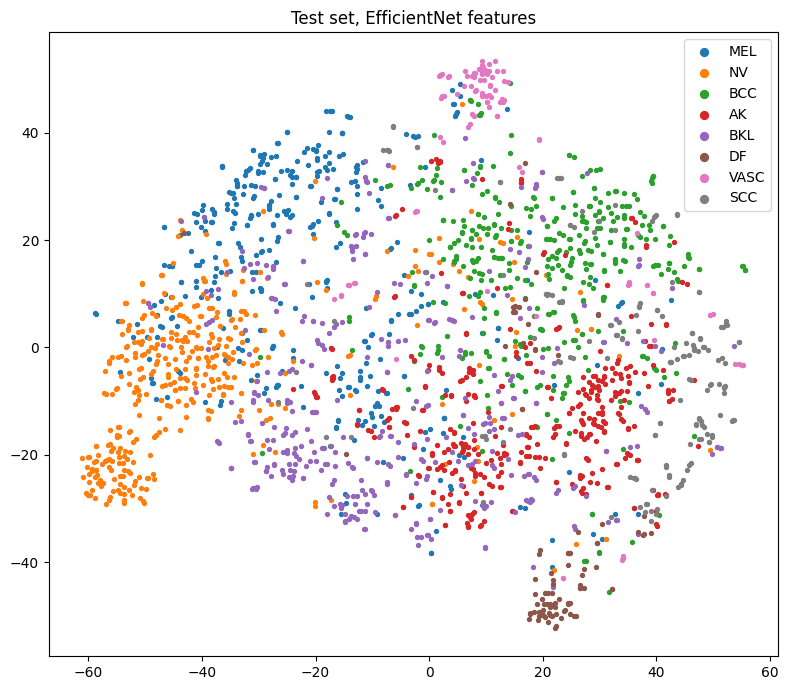

silhouette (8 classes): 0.031


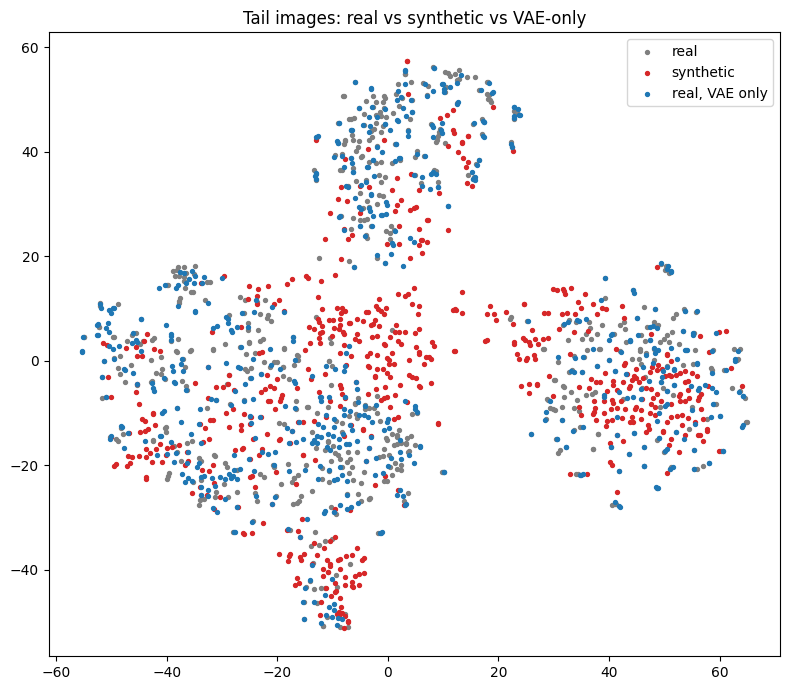

silhouette real vs synthetic: 0.016 | real vs VAE-only: 0.002
G5 DONE


In [13]:
# ===================== CELL G5: t-SNE of EfficientNet features =====================
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
train(Xtr, Ytr, "tsne_cb", 0, loss="cb", save_ckpt=True)
model = make_model(); model.load_state_dict(torch.load(f"{RUNS}/tsne_cb_s0_best.pt", map_location=DEV)); rng = np.random.RandomState(0)
ti = np.concatenate([rng.choice(np.where(Yte == c)[0], min(400, (Yte == c).sum()), replace=False) for c in range(K)])
Z = TSNE(2, perplexity=30, random_state=0, init="pca").fit_transform(feats_of(model, Xte[ti]))
plt.figure(figsize=(8, 7)); [plt.scatter(*Z[Yte[ti] == c].T, s=8, label=classes[c]) for c in range(K)]; plt.legend(markerscale=2); plt.title("Test set, EfficientNet features")
plt.tight_layout(); plt.savefig(f"{REP}/tsne_test_effnet.png", dpi=120); plt.show(); print("silhouette (8 classes):", round(silhouette_score(feats_of(model, Xte[ti]), Yte[ti]), 3))
d = np.load(f"{GEN}/pool_all.npz", allow_pickle=True); P_img, V_img, P_lab = d["img"], d["vae"], d["lab"]
ri = np.concatenate([rng.choice(np.where(rows_tr["class"].values == c)[0], 150, replace=False) for c in tail]); si = np.concatenate([rng.choice(np.where(P_lab == c)[0], 150, replace=False) for c in tail])
Fx = np.concatenate([feats_of(model, Xtr[ri]), feats_of(model, P_img[si]), feats_of(model, V_img[si])]); grp = np.r_[np.zeros(len(ri)), np.ones(len(si)), 2 * np.ones(len(si))].astype(int)
Z2 = TSNE(2, perplexity=30, random_state=0, init="pca").fit_transform(Fx); plt.figure(figsize=(8, 7))
for g, n, col in [(0, "real", "tab:gray"), (1, "synthetic", "tab:red"), (2, "real, VAE only", "tab:blue")]: plt.scatter(*Z2[grp == g].T, s=8, c=col, label=n)
plt.legend(); plt.title("Tail images: real vs synthetic vs VAE-only"); plt.tight_layout(); plt.savefig(f"{REP}/tsne_real_vs_syn_effnet.png", dpi=120); plt.show()
print("silhouette real vs synthetic:", round(silhouette_score(Fx[grp < 2], grp[grp < 2]), 3), "| real vs VAE-only:", round(silhouette_score(Fx[grp != 1], grp[grp != 1]), 3)); print("G5 DONE")

In [14]:
# ===================== CELL G6: closed loop (dose feedback) =====================
ROUNDS = 3; SE_MIN = 0.01
d = np.load(f"{GEN}/pool_all.npz", allow_pickle=True); P_img, P_src, P_lab = d["img"], d["src"], d["lab"]; Sc = pd.read_csv(f"{GEN}/pool_scores.csv"); Pf = np.load(f"{GEN}/pool_feats.npy")
assert os.path.exists(f"{RUNS}/cb_s0_val.npy"), "run the cb baseline (Cell 5) first"
def kcenter(Fm, k):
    k = min(k, len(Fm)); idx = [0]; dd = 1 - Fm @ Fm[0]
    for _ in range(k - 1): j = int(dd.argmax()); idx.append(j); dd = np.minimum(dd, 1 - Fm @ Fm[j])
    return np.array(idx)
def pick(doses):
    sel = []
    for c in tail:
        pc = np.where((P_lab == c) & Sc["gate"].values)[0]
        if len(pc) == 0 or doses[c] <= 0: continue
        sel.append(pc[kcenter(Pf[pc], doses[c])])
    return np.concatenate(sel) if sel else np.array([], int)
def build(sel): return np.concatenate([Xtr, P_img[sel]]), np.concatenate([Ytr, np.array([classes.index(c) for c in P_lab[sel]], dtype=Ytr.dtype)])
doses = {c: 100 for c in tail}; prev = val_recall("cb", 0); hist = []
for r in range(ROUNDS):
    X_, Y_ = build(pick(doses)); train(X_, Y_, f"loop_r{r}", 0, loss="cb"); now = val_recall(f"loop_r{r}", 0); new = dict(doses); row = {"round": r, **{f"dose_{c}": doses[c] for c in tail}}
    for c in tail:
        i = classes.index(c); n = int((Yva == i).sum()); se = max(np.sqrt(max(now[i] * (1 - now[i]), 1e-4) / n), SE_MIN); gain = now[i] - prev[i]; avail = int(((P_lab == c) & Sc["gate"].values).sum())
        if gain > se: new[c] = int(min(doses[c] * 1.5, avail))
        elif gain < -se: new[c] = int(max(doses[c] // 2, 25))
        row[f"gain_{c}"] = round(float(gain), 3)
    hist.append(row); print(row)
    if new == doses: print("no dose changed: stop"); break
    doses, prev = new, now
json.dump({"history": hist, "final_doses": doses}, open(f"{OUT}/loop_history.json", "w"), indent=2); print("final doses:", doses)
X_, Y_ = build(pick(doses))
for sd in (0, 1, 2): train(X_, Y_, "loop_final", sd, loss="cb")
print("G6 DONE")

loop_r0_s0: 23318 training images
  ep 1/12 loss 1.363 | val bma 0.469 | 73s
  ep 2/12 loss 0.798 | val bma 0.563 | 72s
  ep 3/12 loss 0.654 | val bma 0.563 | 72s
  ep 4/12 loss 0.549 | val bma 0.626 | 72s
  ep 5/12 loss 0.470 | val bma 0.579 | 65s
  ep 6/12 loss 0.389 | val bma 0.602 | 65s
  ep 7/12 loss 0.331 | val bma 0.577 | 65s
  ep 8/12 loss 0.281 | val bma 0.597 | 64s
  ep 9/12 loss 0.236 | val bma 0.589 | 64s
  ep 10/12 loss 0.201 | val bma 0.593 | 64s
  ep 11/12 loss 0.191 | val bma 0.592 | 64s
  ep 12/12 loss 0.188 | val bma 0.594 | 65s
{'round': 0, 'dose_AK': 100, 'dose_DF': 100, 'dose_VASC': 100, 'dose_SCC': 100, 'gain_AK': 0.029, 'gain_DF': 0.02, 'gain_VASC': 0.143, 'gain_SCC': -0.056}
loop_r1_s0: 23279 training images
  ep 1/12 loss 1.365 | val bma 0.488 | 73s
  ep 2/12 loss 0.795 | val bma 0.588 | 72s
  ep 3/12 loss 0.642 | val bma 0.534 | 65s
  ep 4/12 loss 0.538 | val bma 0.566 | 65s
  ep 5/12 loss 0.468 | val bma 0.582 | 64s
  ep 6/12 loss 0.390 | val bma 0.560 | 64s
